# Online Retail Sales Analysis

**Module:** Data Visualisation and Communication

**Assessment:** CA2

**Student Name:** Jefferson Arcanjo

**Student Number:** 2023240

**Institution:** CCT College Dublin

 ## 1 - Introduction

This project explores an online retail dataset containing
transactional data from a gift wholesaler.

The company has experienced growth but has not systematically
analysed its sales data. As a result, managers have limited
visibility of product performance, customer behaviour,
regional sales and revenue trends.

The purpose of this analysis is to clean, explore and visualise
the dataset to identify meaningful patterns and provide useful
insights that can support business decisions.

An interactive dashboard will also be developed to allow
managers to explore sales performance using different filters.

###  Business Objectives

The analysis aims to answer the following business questions:

1. How does revenue change over time?
2. Which products generate the highest revenue?
3. Which countries contribute the most to total sales?
4. What is the distribution of customer order values?
5. How does purchasing behaviour vary between customers?
6. Which days and hours experience the highest sales activity?

These questions will guide the exploratory data analysis
and the development of the interactive dashboard.

### Project Methodology

The project is divided into the following stages:

1. Data import and initial exploration.
2. Data quality assessment.
3. Data cleaning and preparation.
4. Feature engineering.
5. Descriptive statistics.
6. Exploratory data analysis and static visualisations.
7. Interactive dashboard development.
8. Business recommendations and limitations.

Python and Jupyter Notebook will be used throughout the
project to combine code, visualisations and written
explanation.

## 2 - Data Import and Initial Exploration

Before cleaning and analysing the dataset, it is important
to understand its structure and the type of information it
contains.

This section focuses on loading the original dataset,
examining its dimensions, identifying the available variables
and checking their data types.

This initial exploration will help identify potential data
quality issues and guide the cleaning process.

In [1]:
# Import the libraries needed for the analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the original dataset

retail_data = pd.read_excel("../data/Online Retail.xlsx")

# Display the first five records

retail_data.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
#  Check the dataset dimensions

print("Number of rows:", retail_data.shape[0])
print("Number of columns:", retail_data.shape[1])

# Display the column names

print("\nColumn names:")
print(retail_data.columns.tolist())

Number of rows: 541909
Number of columns: 8

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [4]:
# Check data types and dataset structure

retail_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


### Variable Description

| Variable | Description |
|---|---|
| InvoiceNo | Order identifier |
| StockCode | Product identifier |
| Description | Product description |
| Quantity | Number of units purchased |
| InvoiceDate | Transaction date and time |
| UnitPrice | Price per unit |
| CustomerID | Customer identifier |
| Country | Customer's country |

Each row represents a transaction line rather than a
complete order, as an invoice can contain multiple products.

### Initial Observations

The dataset contains 541,909 transaction lines and eight
variables, covering product details, quantities, prices,
customer information and countries.

The first five records share the same invoice number,
confirming that an order can contain multiple products.

The initial inspection shows missing values in Description
and CustomerID. InvoiceDate is already stored in datetime
format, while Quantity and UnitPrice are numerical.

These findings will guide the next stage of the data
quality assessment.

## 3 Data Quality Assessment

Before cleaning the dataset, missing values and duplicate
records are examined to understand their impact on data
quality and the reliability of the analysis.

In [5]:
#  Count missing values in each column

missing_values = retail_data.isna().sum()

print(missing_values)

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [6]:
#  Calculate the percentage of missing values

missing_percentage = (missing_values / len(retail_data)) * 100

# Create a summary table

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage (%)": missing_percentage.round(2)
})

missing_summary

,Missing Values,Percentage (%)
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


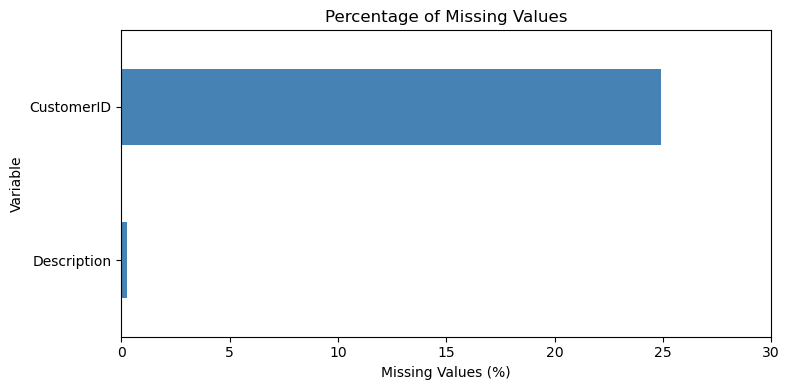

In [7]:
#  Visualise columns with missing values

missing_columns = missing_percentage[missing_percentage > 0]

plt.figure(figsize=(8, 4))

missing_columns.plot(kind="barh", color="steelblue")

plt.title("Percentage of Missing Values")
plt.xlabel("Missing Values (%)")
plt.ylabel("Variable")
plt.xlim(0, 30)

plt.tight_layout()
plt.show()

### Missing Values

CustomerID has the highest proportion of missing values
(24.93%), followed by Description (0.27%).

A horizontal bar chart was selected to make the difference
between the two variables easy to compare.

Missing customer IDs may limit customer behaviour analysis.
However, these records may still contain useful sales
information, so removing them immediately could result
in unnecessary data loss.

In [9]:
# Count duplicate records

duplicate_count = retail_data.duplicated().sum()

duplicate_percentage = (duplicate_count / len(retail_data)) * 100

print("Number of duplicate records:", duplicate_count)
print("Percentage of duplicates:", round(duplicate_percentage, 2), "%")

Number of duplicate records: 5268
Percentage of duplicates: 0.97 %


In [10]:
# Display examples of duplicate records

retail_data[retail_data.duplicated(keep=False)].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom


### Duplicate Records

The dataset contains 5,268 additional duplicate records,
representing 0.97% of the original data.

Identical records were examined across all eight variables.
If these records are duplicated in error, they could lead
to an overestimation of sales quantities and revenue.

However, some identical records may represent legitimate
repeated purchases. This limitation will be considered
during the cleaning process.